In [43]:
# 1. Environment Setup and Output Directories

from pathlib import Path
import os
import gc
import time
import math
import random
import numpy as np
import pandas as pd

# from the repository root or from the notebooks/ directory.
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = PROJECT_ROOT / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIG_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/PhD/RAREGuard_v5
Results directory: /content/drive/MyDrive/PhD/RAREGuard_v5/results
Figures directory: /content/drive/MyDrive/PhD/RAREGuard_v5/figures


In [30]:
# 2. Library Imports

from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.neighbors import kneighbors_graph
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix,
    precision_recall_curve
)

import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [42]:
# 3. Load Dataset

csv_path = DATA_DIR / "creditcard.csv"

if not csv_path.exists():
    raise FileNotFoundError(
        "creditcard.csv was not found.\n"
        "Download the Credit Card Fraud Detection dataset from Kaggle "
        "and place it in data/raw/creditcard.csv"
    )

df = pd.read_csv(csv_path)

X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

feature_names = X.columns.tolist()

X_raw = X.values.astype(np.float32)
y_raw = y.values.astype(int)

print("Dataset shape:", df.shape)
print("Fraud count:", y_raw.sum())
print(
    "Fraud percentage:",
    round(y_raw.mean() * 100, 4),
    "%"
)

Dataset shape: (284807, 31)
Fraud count: 492
Fraud percentage: 0.1727 %


In [9]:
# 4. Reproducibility and Evaluation Utilities

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def laplacian_score(X, k=10):
    W = kneighbors_graph(
        X,
        n_neighbors=k,
        mode="connectivity",
        include_self=True
    ).tocsr()

    D = np.asarray(W.sum(axis=1)).ravel().astype(np.float32)
    d_sum = D.sum() + 1e-12

    scores = np.zeros(X.shape[1], dtype=np.float32)

    for j in range(X.shape[1]):
        f = X[:, j].astype(np.float32)
        f_bar = (D @ f) / d_sum
        f_tilde = f - f_bar

        fDf = (D * f_tilde) @ f_tilde
        fWf = f_tilde @ (W @ f_tilde)

        scores[j] = (fDf - fWf) / (fDf + 1e-12)

    return scores


def normalize_scores(train_scores, val_scores, test_scores):
    s_min = np.min(train_scores)
    s_max = np.max(train_scores)
    denom = s_max - s_min + 1e-12

    return (
        (train_scores - s_min) / denom,
        (val_scores - s_min) / denom,
        (test_scores - s_min) / denom
    )


def pick_threshold_by_val_f1(y_val, val_scores, pmin=80, pmax=99.9, ngrid=200):
    best_f1 = -1
    best_threshold = None

    thresholds = np.percentile(val_scores, np.linspace(pmin, pmax, ngrid))

    for th in thresholds:
        y_pred = (val_scores >= th).astype(int)

        p, r, f1, _ = precision_recall_fscore_support(
            y_val,
            y_pred,
            average="binary",
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = th

    return best_threshold, best_f1


def pick_threshold_unsupervised(scores, contamination=0.002):
    percentile = 100 * (1 - contamination)
    return np.percentile(scores, percentile)


def evaluate_scores(y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    roc = roc_auc_score(y_true, scores)
    pr = average_precision_score(y_true, scores)
    mcc = matthews_corrcoef(y_true, y_pred)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "Precision": p,
        "Recall": r,
        "F1": f1,
        "ROC_AUC": roc,
        "PR_AUC": pr,
        "MCC": mcc,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    }

In [10]:
# 5. Autoencoder Architecture

class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

In [11]:
# 6. Preprocessing and Hybrid Feature Engineering

def prepare_features(
    X_train,
    X_val,
    X_test,
    y_train,
    seed=42,
    use_feature_selection=True,
    use_pca=True
):
    """
    Preprocessing + optional hybrid feature selection + optional PCA.
    """

    imputer = KNNImputer(n_neighbors=5)

    X_train_i = imputer.fit_transform(X_train).astype(np.float32)
    X_val_i = imputer.transform(X_val).astype(np.float32)
    X_test_i = imputer.transform(X_test).astype(np.float32)

    scaler = MinMaxScaler()

    X_train_s = scaler.fit_transform(X_train_i).astype(np.float32)
    X_val_s = scaler.transform(X_val_i).astype(np.float32)
    X_test_s = scaler.transform(X_test_i).astype(np.float32)

    selected_features = feature_names.copy()

    if use_feature_selection:
        vt = VarianceThreshold(threshold=1e-5)

        X_train_vt = vt.fit_transform(X_train_s).astype(np.float32)
        X_val_vt = vt.transform(X_val_s).astype(np.float32)
        X_test_vt = vt.transform(X_test_s).astype(np.float32)

        vt_idx = np.where(vt.get_support())[0]
        vt_features = [feature_names[i] for i in vt_idx]

        sample_n = min(5000, X_train_vt.shape[0])
        rng = np.random.RandomState(seed)
        sample_idx = rng.choice(X_train_vt.shape[0], size=sample_n, replace=False)

        lap_scores = laplacian_score(X_train_vt[sample_idx], k=10)

        k_features = min(20, X_train_vt.shape[1])
        lap_idx = np.argsort(lap_scores)[:k_features]

        selected_features = [vt_features[i] for i in lap_idx]

        X_train_final = X_train_vt[:, lap_idx].astype(np.float32)
        X_val_final = X_val_vt[:, lap_idx].astype(np.float32)
        X_test_final = X_test_vt[:, lap_idx].astype(np.float32)

    else:
        X_train_final = X_train_s
        X_val_final = X_val_s
        X_test_final = X_test_s

    if use_pca:
        pca = PCA(n_components=0.95, random_state=seed)

        X_train_final = pca.fit_transform(X_train_final).astype(np.float32)
        X_val_final = pca.transform(X_val_final).astype(np.float32)
        X_test_final = pca.transform(X_test_final).astype(np.float32)

        pca_dims = X_train_final.shape[1]

    else:
        pca = None
        pca_dims = X_train_final.shape[1]

    return X_train_final, X_val_final, X_test_final, selected_features, pca_dims

In [12]:
# 7. Base Detectors and Weighted Score Fusion

def run_models(
    X_train_best,
    X_val_best,
    X_test_best,
    y_train,
    y_val,
    y_test,
    seed=42,
    model_mode="RAREGuard"
):
    """
    model_mode options:
    IF, OCSVM, AE, RAREGuard
    """

    set_seed(seed)

    scores = {}

    total_train_start = time.time()

    if model_mode in ["IF", "RAREGuard"]:
        if_model = IsolationForest(
            n_estimators=300,
            contamination="auto",
            random_state=seed,
            n_jobs=-1
        )

        if_model.fit(X_train_best)

        if_train = -if_model.decision_function(X_train_best)
        if_val = -if_model.decision_function(X_val_best)
        if_test = -if_model.decision_function(X_test_best)

        if_train_n, if_val_n, if_test_n = normalize_scores(if_train, if_val, if_test)

        scores["IF"] = (if_train_n, if_val_n, if_test_n)

    if model_mode in ["OCSVM", "RAREGuard"]:
        normal_idx = np.where(y_train == 0)[0]
        sample_size = min(30000, len(normal_idx))

        rng = np.random.RandomState(seed)
        oc_idx = rng.choice(normal_idx, size=sample_size, replace=False)

        ocsvm = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.002
        )

        ocsvm.fit(X_train_best[oc_idx])

        oc_train = -ocsvm.decision_function(X_train_best).ravel()
        oc_val = -ocsvm.decision_function(X_val_best).ravel()
        oc_test = -ocsvm.decision_function(X_test_best).ravel()

        oc_train_n, oc_val_n, oc_test_n = normalize_scores(oc_train, oc_val, oc_test)

        scores["OCSVM"] = (oc_train_n, oc_val_n, oc_test_n)

    if model_mode in ["AE", "RAREGuard"]:
        input_dim = X_train_best.shape[1]

        ae = Autoencoder(input_dim).to(device)

        optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
        criterion = nn.MSELoss()

        X_train_tensor = torch.tensor(X_train_best, dtype=torch.float32)
        y_train_tensor = torch.tensor(y_train, dtype=torch.long)

        X_train_normal = X_train_tensor[y_train_tensor == 0]

        train_loader = DataLoader(
            TensorDataset(X_train_normal),
            batch_size=1024,
            shuffle=True
        )

        X_train_all_tensor = torch.tensor(X_train_best, dtype=torch.float32).to(device)
        X_val_tensor = torch.tensor(X_val_best, dtype=torch.float32).to(device)
        X_test_tensor = torch.tensor(X_test_best, dtype=torch.float32).to(device)

        epochs = 30
        patience = 5
        best_val_loss = math.inf
        no_improve = 0
        best_state = None

        for epoch in range(1, epochs + 1):
            ae.train()

            for (batch,) in train_loader:
                batch = batch.to(device)

                optimizer.zero_grad()
                recon = ae(batch)
                loss = criterion(recon, batch)
                loss.backward()
                optimizer.step()

            ae.eval()
            with torch.no_grad():
                val_recon = ae(X_val_tensor)
                val_loss = criterion(val_recon, X_val_tensor).item()

            if val_loss < best_val_loss - 1e-7:
                best_val_loss = val_loss
                no_improve = 0
                best_state = {k: v.cpu().clone() for k, v in ae.state_dict().items()}
            else:
                no_improve += 1

            if no_improve >= patience:
                break

        if best_state is not None:
            ae.load_state_dict(best_state)

        ae.eval()

        with torch.no_grad():
            train_recon = ae(X_train_all_tensor)
            val_recon = ae(X_val_tensor)
            test_recon = ae(X_test_tensor)

            ae_train = ((train_recon - X_train_all_tensor) ** 2).mean(dim=1).cpu().numpy()
            ae_val = ((val_recon - X_val_tensor) ** 2).mean(dim=1).cpu().numpy()
            ae_test = ((test_recon - X_test_tensor) ** 2).mean(dim=1).cpu().numpy()

        ae_train_n, ae_val_n, ae_test_n = normalize_scores(ae_train, ae_val, ae_test)

        scores["AE"] = (ae_train_n, ae_val_n, ae_test_n)

    train_time = time.time() - total_train_start

    if model_mode == "IF":
        final_train, final_val, final_test = scores["IF"]

    elif model_mode == "OCSVM":
        final_train, final_val, final_test = scores["OCSVM"]

    elif model_mode == "AE":
        final_train, final_val, final_test = scores["AE"]

    else:
        if_train_n, if_val_n, if_test_n = scores["IF"]
        oc_train_n, oc_val_n, oc_test_n = scores["OCSVM"]
        ae_train_n, ae_val_n, ae_test_n = scores["AE"]

        final_train = 0.30 * if_train_n + 0.30 * oc_train_n + 0.40 * ae_train_n
        final_val = 0.30 * if_val_n + 0.30 * oc_val_n + 0.40 * ae_val_n
        final_test = 0.30 * if_test_n + 0.30 * oc_test_n + 0.40 * ae_test_n

    return final_val, final_test, train_time

In [13]:
# 8. End-to-End Experimental Pipeline

def run_experiment(
    seed=42,
    experiment_name="RAREGuard_Full",
    use_feature_selection=True,
    use_pca=True,
    model_mode="RAREGuard",
    threshold_mode="label",
    contamination=0.002
):
    set_seed(seed)

    start_total = time.time()

    X_train, X_temp, y_train, y_temp = train_test_split(
        X_raw,
        y_raw,
        test_size=0.30,
        stratify=y_raw,
        random_state=seed
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=seed
    )

    X_train_best, X_val_best, X_test_best, selected_features, pca_dims = prepare_features(
        X_train,
        X_val,
        X_test,
        y_train,
        seed=seed,
        use_feature_selection=use_feature_selection,
        use_pca=use_pca
    )

    val_scores, test_scores, train_time = run_models(
        X_train_best,
        X_val_best,
        X_test_best,
        y_train,
        y_val,
        y_test,
        seed=seed,
        model_mode=model_mode
    )

    if threshold_mode == "label":
        threshold, val_f1 = pick_threshold_by_val_f1(
            y_val,
            val_scores
        )
        threshold_label = "Label-assisted"

    elif threshold_mode == "unsupervised":
        threshold = pick_threshold_unsupervised(
            val_scores,
            contamination=contamination
        )
        val_f1 = None
        threshold_label = "Fully unsupervised"

    else:
        raise ValueError(
            "threshold_mode must be 'label' or 'unsupervised'"
        )

    metrics = evaluate_scores(
        y_test,
        test_scores,
        threshold
    )

    total_time = time.time() - start_total

    return {
        "Seed": seed,
        "Experiment": experiment_name,
        "Model": model_mode,
        "Threshold Mode": threshold_label,
        "Contamination": (
            contamination
            if threshold_mode == "unsupervised"
            else np.nan
        ),
        "Feature Selection": use_feature_selection,
        "PCA": use_pca,
        "Selected Features": len(selected_features),
        "PCA Dimensions": pca_dims,
        "Threshold": threshold,
        "Validation F1": val_f1,
        "Train Time": train_time,
        "Total Time": total_time,
        **metrics
    }

In [14]:
# 9. Experimental Configurations and Random Seeds

experiments = [
    {
        "experiment_name": "IF_Only",
        "use_feature_selection": True,
        "use_pca": True,
        "model_mode": "IF"
    },
    {
        "experiment_name": "OCSVM_Only",
        "use_feature_selection": True,
        "use_pca": True,
        "model_mode": "OCSVM"
    },
    {
        "experiment_name": "AE_Only",
        "use_feature_selection": True,
        "use_pca": True,
        "model_mode": "AE"
    },
    {
        "experiment_name": "RAREGuard_No_FS",
        "use_feature_selection": False,
        "use_pca": True,
        "model_mode": "RAREGuard"
    },
    {
        "experiment_name": "RAREGuard_No_PCA",
        "use_feature_selection": True,
        "use_pca": False,
        "model_mode": "RAREGuard"
    },
    {
        "experiment_name": "RAREGuard_Full",
        "use_feature_selection": True,
        "use_pca": True,
        "model_mode": "RAREGuard"
    }
]

seeds = [42, 7, 21, 100, 2026]

print("Experiments:", len(experiments))
print("Seeds:", seeds)

Experiments: 6
Seeds: [42, 7, 21, 100, 2026]


In [15]:
# 10. Label-Assisted Thresholding Experiments

label_results = []

for seed in seeds:
    for exp in experiments:
        print("Running:", exp["experiment_name"], "| Seed:", seed)

        result = run_experiment(
            seed=seed,
            threshold_mode="label",
            **exp
        )

        label_results.append(result)
        gc.collect()

label_results_df = pd.DataFrame(label_results)
label_results_df

Running: IF_Only | Seed: 42
Running: OCSVM_Only | Seed: 42
Running: AE_Only | Seed: 42
Running: RAREGuard_No_FS | Seed: 42
Running: RAREGuard_No_PCA | Seed: 42
Running: RAREGuard_Full | Seed: 42
Running: IF_Only | Seed: 7
Running: OCSVM_Only | Seed: 7
Running: AE_Only | Seed: 7
Running: RAREGuard_No_FS | Seed: 7
Running: RAREGuard_No_PCA | Seed: 7
Running: RAREGuard_Full | Seed: 7
Running: IF_Only | Seed: 21
Running: OCSVM_Only | Seed: 21
Running: AE_Only | Seed: 21
Running: RAREGuard_No_FS | Seed: 21
Running: RAREGuard_No_PCA | Seed: 21
Running: RAREGuard_Full | Seed: 21
Running: IF_Only | Seed: 100
Running: OCSVM_Only | Seed: 100
Running: AE_Only | Seed: 100
Running: RAREGuard_No_FS | Seed: 100
Running: RAREGuard_No_PCA | Seed: 100
Running: RAREGuard_Full | Seed: 100
Running: IF_Only | Seed: 2026
Running: OCSVM_Only | Seed: 2026
Running: AE_Only | Seed: 2026
Running: RAREGuard_No_FS | Seed: 2026
Running: RAREGuard_No_PCA | Seed: 2026
Running: RAREGuard_Full | Seed: 2026


,Seed,Experiment,Model,Threshold Mode,Contamination,Feature Selection,PCA,Selected Features,PCA Dimensions,Threshold,...,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,TP,FP,TN,FN
0,42,IF_Only,IF,Label-assisted,NaN,True,True,20,12,0.566674,...,0.357724,0.594595,0.446701,0.914303,0.388279,0.460022,44,79,42569,30
1,42,OCSVM_Only,OCSVM,Label-assisted,NaN,True,True,20,12,0.720572,...,0.658537,0.364865,0.469565,0.899557,0.442962,0.489550,27,14,42634,47
2,42,AE_Only,AE,Label-assisted,NaN,True,True,20,12,0.038049,...,0.237500,0.256757,0.246753,0.934798,0.233993,0.245582,19,61,42587,55
3,42,RAREGuard_No_FS,RAREGuard,Label-assisted,NaN,False,True,30,13,0.373597,...,0.536232,0.500000,0.517483,0.915368,0.494048,0.516992,37,32,42616,37
4,42,RAREGuard_No_PCA,RAREGuard,Label-assisted,NaN,True,False,20,20,0.330913,...,0.573529,0.527027,0.549296,0.940969,0.528364,0.549039,39,29,42619,35
5,42,RAREGuard_Full,RAREGuard,Label-assisted,NaN,True,True,20,12,0.365078,...,0.493151,0.486486,0.489796,0.913364,0.481565,0.488928,36,37,42611,38
6,7,IF_Only,IF,Label-assisted,NaN,True,True,20,12,0.586598,...,0.336538,0.472973,0.393258,0.913970,0.340371,0.397741,35,69,42579,39
7,7,OCSVM_Only,OCSVM,Label-assisted,NaN,True,True,20,12,0.599292,...,0.408163,0.540541,0.465116,0.900949,0.464015,0.468662,40,58,42590,34
8,7,AE_Only,AE,Label-assisted,NaN,True,True,20,12,0.019248,...,0.520833,0.337838,0.409836,0.894220,0.370204,0.418675,25,23,42625,49
9,7,RAREGuard_No_FS,RAREGuard,Label-assisted,NaN,False,True,30,13,0.347946,...,0.366071,0.554054,0.440860,0.908569,0.460810,0.449206,41,71,42577,33


In [44]:
# 11. Save Label-Assisted Results

label_results_path = RESULTS_DIR / "label_assisted_results.csv"
label_results_df.to_csv(label_results_path, index=False)
print("Saved:", label_results_path)

Saved: /content/drive/MyDrive/PhD/RAREGuard_v5/results/label_assisted_results.csv


In [17]:
# 12. Fully Unsupervised Thresholding Experiments

unsup_results = []

for seed in seeds:
    for exp in experiments:
        print("Running:", exp["experiment_name"], "| Seed:", seed)

        result = run_experiment(
            seed=seed,
            threshold_mode="unsupervised",
            **exp
        )

        unsup_results.append(result)
        gc.collect()

unsup_results_df = pd.DataFrame(unsup_results)
unsup_results_df

Running: IF_Only | Seed: 42
Running: OCSVM_Only | Seed: 42
Running: AE_Only | Seed: 42
Running: RAREGuard_No_FS | Seed: 42
Running: RAREGuard_No_PCA | Seed: 42
Running: RAREGuard_Full | Seed: 42
Running: IF_Only | Seed: 7
Running: OCSVM_Only | Seed: 7
Running: AE_Only | Seed: 7
Running: RAREGuard_No_FS | Seed: 7
Running: RAREGuard_No_PCA | Seed: 7
Running: RAREGuard_Full | Seed: 7
Running: IF_Only | Seed: 21
Running: OCSVM_Only | Seed: 21
Running: AE_Only | Seed: 21
Running: RAREGuard_No_FS | Seed: 21
Running: RAREGuard_No_PCA | Seed: 21
Running: RAREGuard_Full | Seed: 21
Running: IF_Only | Seed: 100
Running: OCSVM_Only | Seed: 100
Running: AE_Only | Seed: 100
Running: RAREGuard_No_FS | Seed: 100
Running: RAREGuard_No_PCA | Seed: 100
Running: RAREGuard_Full | Seed: 100
Running: IF_Only | Seed: 2026
Running: OCSVM_Only | Seed: 2026
Running: AE_Only | Seed: 2026
Running: RAREGuard_No_FS | Seed: 2026
Running: RAREGuard_No_PCA | Seed: 2026
Running: RAREGuard_Full | Seed: 2026


,Seed,Experiment,Model,Threshold Mode,Contamination,Feature Selection,PCA,Selected Features,PCA Dimensions,Threshold,...,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,TP,FP,TN,FN
0,42,IF_Only,IF,Fully unsupervised,0.002,True,True,20,12,0.597993,...,0.417582,0.513514,0.460606,0.914303,0.388279,0.462042,38,53,42595,36
1,42,OCSVM_Only,OCSVM,Fully unsupervised,0.002,True,True,20,12,0.614415,...,0.462500,0.500000,0.480519,0.899557,0.442962,0.479949,37,43,42605,37
2,42,AE_Only,AE,Fully unsupervised,0.002,True,True,20,12,0.038049,...,0.237500,0.256757,0.246753,0.934798,0.233993,0.245582,19,61,42587,55
3,42,RAREGuard_No_FS,RAREGuard,Fully unsupervised,0.002,False,True,30,13,0.373597,...,0.536232,0.500000,0.517483,0.915368,0.494048,0.516992,37,32,42616,37
4,42,RAREGuard_No_PCA,RAREGuard,Fully unsupervised,0.002,True,False,20,20,0.330913,...,0.573529,0.527027,0.549296,0.940969,0.528364,0.549039,39,29,42619,35
5,42,RAREGuard_Full,RAREGuard,Fully unsupervised,0.002,True,True,20,12,0.365078,...,0.493151,0.486486,0.489796,0.913364,0.481565,0.488928,36,37,42611,38
6,7,IF_Only,IF,Fully unsupervised,0.002,True,True,20,12,0.586598,...,0.336538,0.472973,0.393258,0.913970,0.340371,0.397741,35,69,42579,39
7,7,OCSVM_Only,OCSVM,Fully unsupervised,0.002,True,True,20,12,0.599292,...,0.408163,0.540541,0.465116,0.900949,0.464015,0.468662,40,58,42590,34
8,7,AE_Only,AE,Fully unsupervised,0.002,True,True,20,12,0.009883,...,0.326316,0.418919,0.366864,0.894220,0.370204,0.368496,31,64,42584,43
9,7,RAREGuard_No_FS,RAREGuard,Fully unsupervised,0.002,False,True,30,13,0.347946,...,0.366071,0.554054,0.440860,0.908569,0.460810,0.449206,41,71,42577,33


In [18]:
# 13. Contamination-Rate Sensitivity Analysis
# Train once per seed and vary only the decision threshold
contamination_values = [
    0.001,
    0.0015,
    0.002,
    0.003,
    0.005
]

contamination_results = []

for seed in seeds:

    print("Training RAREGuard Full | Seed:", seed)

    set_seed(seed)


    # Train / validation / test split

    X_train, X_temp, y_train, y_temp = train_test_split(
        X_raw,
        y_raw,
        test_size=0.30,
        stratify=y_raw,
        random_state=seed
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=seed
    )


    # Full RAREGuard feature pipeline

    (
        X_train_best,
        X_val_best,
        X_test_best,
        selected_features,
        pca_dims
    ) = prepare_features(
        X_train,
        X_val,
        X_test,
        y_train,
        seed=seed,
        use_feature_selection=True,
        use_pca=True
    )


    # Train RAREGuard once

    val_scores, test_scores, train_time = run_models(
        X_train_best,
        X_val_best,
        X_test_best,
        y_train,
        y_val,
        y_test,
        seed=seed,
        model_mode="RAREGuard"
    )


    # Vary threshold contamination only

    for contamination in contamination_values:

        threshold = pick_threshold_unsupervised(
            val_scores,
            contamination=contamination
        )

        metrics = evaluate_scores(
            y_test,
            test_scores,
            threshold
        )

        contamination_results.append({
            "Seed": seed,
            "Experiment": "RAREGuard_Full",
            "Threshold Mode": "Fully unsupervised",
            "Contamination": contamination,
            "Threshold": threshold,
            "Selected Features": len(selected_features),
            "PCA Dimensions": pca_dims,
            "Train Time": train_time,
            **metrics
        })

contamination_results_df = pd.DataFrame(
    contamination_results
)

contamination_results_df

Training RAREGuard Full | Seed: 42
Training RAREGuard Full | Seed: 7
Training RAREGuard Full | Seed: 21
Training RAREGuard Full | Seed: 100
Training RAREGuard Full | Seed: 2026


,Seed,Experiment,Threshold Mode,Contamination,Threshold,Selected Features,PCA Dimensions,Train Time,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,TP,FP,TN,FN
0,42,RAREGuard_Full,Fully unsupervised,0.0010,0.425100,20,12,65.385041,0.700000,0.378378,0.491228,0.913364,0.481565,0.514063,28,12,42636,46
1,42,RAREGuard_Full,Fully unsupervised,0.0015,0.391254,20,12,65.385041,0.636364,0.472973,0.542636,0.913364,0.481565,0.547953,35,20,42628,39
2,42,RAREGuard_Full,Fully unsupervised,0.0020,0.365078,20,12,65.385041,0.493151,0.486486,0.489796,0.913364,0.481565,0.488928,36,37,42611,38
3,42,RAREGuard_Full,Fully unsupervised,0.0030,0.340760,20,12,65.385041,0.367925,0.527027,0.433333,0.913364,0.481565,0.439200,39,67,42581,35
4,42,RAREGuard_Full,Fully unsupervised,0.0050,0.316052,20,12,65.385041,0.242424,0.648649,0.352941,0.913364,0.481565,0.394970,48,150,42498,26
5,7,RAREGuard_Full,Fully unsupervised,0.0010,0.417268,20,12,64.522609,0.744186,0.432432,0.547009,0.912553,0.473416,0.566739,32,11,42637,42
6,7,RAREGuard_Full,Fully unsupervised,0.0015,0.367501,20,12,64.522609,0.527027,0.527027,0.527027,0.912553,0.473416,0.526206,39,35,42613,35
7,7,RAREGuard_Full,Fully unsupervised,0.0020,0.343079,20,12,64.522609,0.386792,0.554054,0.455556,0.912553,0.473416,0.461830,41,65,42583,33
8,7,RAREGuard_Full,Fully unsupervised,0.0030,0.321938,20,12,64.522609,0.265432,0.581081,0.364407,0.912553,0.473416,0.391249,43,119,42529,31
9,7,RAREGuard_Full,Fully unsupervised,0.0050,0.304246,20,12,64.522609,0.192469,0.621622,0.293930,0.912553,0.473416,0.344042,46,193,42455,28


In [19]:
# 14. Contamination Sensitivity Summary Statistics

sensitivity_metrics = [
    "Precision",
    "Recall",
    "F1",
    "MCC",
    "PR_AUC",
    "ROC_AUC",
    "TP",
    "FP",
    "TN",
    "FN",
    "Threshold"
]

contamination_summary_mean = (
    contamination_results_df
    .groupby("Contamination")[sensitivity_metrics]
    .mean()
    .reset_index()
)

contamination_summary_std = (
    contamination_results_df
    .groupby("Contamination")[sensitivity_metrics]
    .std()
    .reset_index()
)

display(contamination_summary_mean)
display(contamination_summary_std)

,Contamination,Precision,Recall,F1,MCC,PR_AUC,ROC_AUC,TP,FP,TN,FN,Threshold
0,0.0010,0.668004,0.421622,0.515636,0.529355,0.487214,0.922768,31.2,15.8,42632.2,42.8,0.425791
1,0.0015,0.559999,0.543243,0.548967,0.549519,0.487214,0.922768,40.2,32.2,42615.8,33.8,0.384907
2,0.0020,0.459522,0.570270,0.507008,0.509990,0.487214,0.922768,42.2,50.4,42597.6,31.8,0.364301
3,0.0030,0.332349,0.610811,0.428539,0.448213,0.487214,0.922768,45.2,92.6,42555.4,28.8,0.340283
4,0.0050,0.229840,0.670270,0.341981,0.390617,0.487214,0.922768,49.6,167.6,42480.4,24.4,0.317361


,Contamination,Precision,Recall,F1,MCC,PR_AUC,ROC_AUC,TP,FP,TN,FN,Threshold
0,0.0010,0.052921,0.025994,0.020985,0.021987,0.05336,0.016802,1.923538,4.086563,4.086563,1.923538,0.024649
1,0.0015,0.047937,0.046223,0.021859,0.021609,0.05336,0.016802,3.420526,7.190271,7.190271,3.420526,0.019963
2,0.0020,0.050025,0.059213,0.043451,0.042900,0.05336,0.016802,4.381780,10.667708,10.667708,4.381780,0.021910
3,0.0030,0.042463,0.058437,0.040442,0.038366,0.05336,0.016802,4.324350,19.346834,19.346834,4.324350,0.015015
4,0.0050,0.027572,0.047394,0.035772,0.035765,0.05336,0.016802,3.507136,18.915602,18.915602,3.507136,0.011118


In [45]:

# 15. Prepare and Save Contamination Sensitivity Results


classification_metrics = [
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

# Build publication-ready mean ± standard deviation table
sensitivity_table = pd.DataFrame({
    "Contamination": contamination_summary_mean["Contamination"]
})

for metric in classification_metrics:

    mean_values = contamination_summary_mean[metric]
    std_values = contamination_summary_std[metric]

    sensitivity_table[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(mean_values, std_values)
    ]

# Display the final table
display(sensitivity_table)

# Save the table
sensitivity_table_path = RESULTS_DIR/ "contamination_sensitivity_analysis.csv"

sensitivity_table.to_csv(
    sensitivity_table_path,
    index=False
)

print("Saved:", sensitivity_table_path)

,Contamination,Precision,Recall,F1,MCC
0,0.0010,0.6680 ± 0.0529,0.4216 ± 0.0260,0.5156 ± 0.0210,0.5294 ± 0.0220
1,0.0015,0.5600 ± 0.0479,0.5432 ± 0.0462,0.5490 ± 0.0219,0.5495 ± 0.0216
2,0.0020,0.4595 ± 0.0500,0.5703 ± 0.0592,0.5070 ± 0.0435,0.5100 ± 0.0429
3,0.0030,0.3323 ± 0.0425,0.6108 ± 0.0584,0.4285 ± 0.0404,0.4482 ± 0.0384
4,0.0050,0.2298 ± 0.0276,0.6703 ± 0.0474,0.3420 ± 0.0358,0.3906 ± 0.0358


Saved: /content/drive/MyDrive/PhD/RAREGuard_v5/results/contamination_sensitivity_analysis.csv


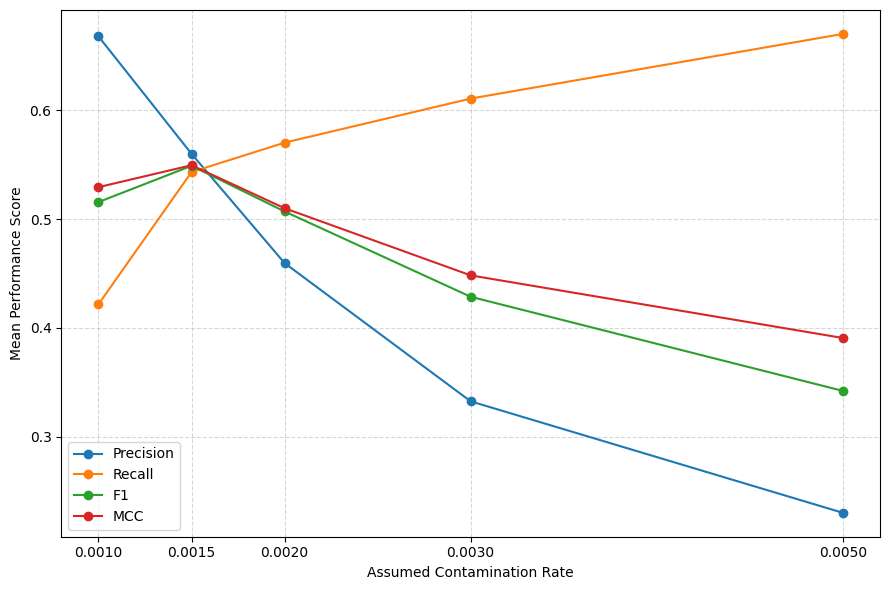

Saved: /content/drive/MyDrive/PhD/RAREGuard_v5/figures/figure_5_contamination_sensitivity.png


In [38]:
# 16. Figure 5 — Contamination-Rate Sensitivity

plot_metrics = [
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

plt.figure(figsize=(9, 6))

for metric in plot_metrics:
    plt.plot(
        contamination_summary_mean["Contamination"],
        contamination_summary_mean[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Assumed Contamination Rate")
plt.ylabel("Mean Performance Score")

plt.xticks(contamination_values)
plt.legend()
plt.grid(
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

sensitivity_figure_path = FIG_DIR/"figure_5_contamination_sensitivity.png"


plt.savefig(
    sensitivity_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", sensitivity_figure_path)

In [47]:
# 17. Save Fully Unsupervised Results
unsup_results_path = RESULTS_DIR/"fully_unsupervised_results.csv"
unsup_results_df.to_csv(unsup_results_path, index=False)
print("Saved:", unsup_results_path)

Saved: /content/drive/MyDrive/PhD/RAREGuard_v5/results/fully_unsupervised_results.csv


In [53]:
# 18. Combine Label-Assisted and Fully Unsupervised Results

all_results_df = pd.concat(
    [label_results_df, unsup_results_df],
    ignore_index=True
)

# Save the complete experimental results
all_results_path = RESULTS_DIR/"all_experimental_results.csv"

all_results_df.to_csv(
    all_results_path,
    index=False
)

print("Saved:", all_results_path)
print("Total experimental rows:", len(all_results_df))

display(all_results_df)

Saved: /content/drive/MyDrive/PhD/RAREGuard_v5/results/all_experimental_results.csv
Total experimental rows: 60


/tmp/ipykernel_1748/2424354981.py:3: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_results_df = pd.concat(


,Seed,Experiment,Model,Threshold Mode,Contamination,Feature Selection,PCA,Selected Features,PCA Dimensions,Threshold,...,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,TP,FP,TN,FN
0,42,IF_Only,IF,Label-assisted,NaN,True,True,20,12,0.566674,...,0.357724,0.594595,0.446701,0.914303,0.388279,0.460022,44,79,42569,30
1,42,OCSVM_Only,OCSVM,Label-assisted,NaN,True,True,20,12,0.720572,...,0.658537,0.364865,0.469565,0.899557,0.442962,0.489550,27,14,42634,47
2,42,AE_Only,AE,Label-assisted,NaN,True,True,20,12,0.038049,...,0.237500,0.256757,0.246753,0.934798,0.233993,0.245582,19,61,42587,55
3,42,RAREGuard_No_FS,RAREGuard,Label-assisted,NaN,False,True,30,13,0.373597,...,0.536232,0.500000,0.517483,0.915368,0.494048,0.516992,37,32,42616,37
4,42,RAREGuard_No_PCA,RAREGuard,Label-assisted,NaN,True,False,20,20,0.330913,...,0.573529,0.527027,0.549296,0.940969,0.528364,0.549039,39,29,42619,35
5,42,RAREGuard_Full,RAREGuard,Label-assisted,NaN,True,True,20,12,0.365078,...,0.493151,0.486486,0.489796,0.913364,0.481565,0.488928,36,37,42611,38
6,7,IF_Only,IF,Label-assisted,NaN,True,True,20,12,0.586598,...,0.336538,0.472973,0.393258,0.913970,0.340371,0.397741,35,69,42579,39
7,7,OCSVM_Only,OCSVM,Label-assisted,NaN,True,True,20,12,0.599292,...,0.408163,0.540541,0.465116,0.900949,0.464015,0.468662,40,58,42590,34
8,7,AE_Only,AE,Label-assisted,NaN,True,True,20,12,0.019248,...,0.520833,0.337838,0.409836,0.894220,0.370204,0.418675,25,23,42625,49
9,7,RAREGuard_No_FS,RAREGuard,Label-assisted,NaN,False,True,30,13,0.347946,...,0.366071,0.554054,0.440860,0.908569,0.460810,0.449206,41,71,42577,33


In [24]:
# 19. Mean and Standard-Deviation Summary Across Seeds

metrics_cols = [
    "Precision",
    "Recall",
    "F1",
    "PR_AUC",
    "ROC_AUC",
    "MCC",
    "Train Time",
    "Total Time"
]

summary_mean = all_results_df.groupby(
    ["Threshold Mode", "Experiment"]
)[metrics_cols].mean().reset_index()

summary_std = all_results_df.groupby(
    ["Threshold Mode", "Experiment"]
)[metrics_cols].std().reset_index()

summary_mean

,Threshold Mode,Experiment,Precision,Recall,F1,PR_AUC,ROC_AUC,MCC,Train Time,Total Time
0,Fully unsupervised,AE_Only,0.363948,0.416216,0.387708,0.356912,0.911415,0.387753,56.748667,57.682432
1,Fully unsupervised,IF_Only,0.405643,0.540541,0.463132,0.388612,0.925085,0.467026,7.087571,7.938345
2,Fully unsupervised,OCSVM_Only,0.444972,0.532432,0.483620,0.457693,0.908432,0.485178,3.214012,3.999413
3,Fully unsupervised,RAREGuard_Full,0.459522,0.570270,0.507008,0.487214,0.922768,0.509990,66.153668,67.103794
4,Fully unsupervised,RAREGuard_No_FS,0.447055,0.575676,0.499710,0.487485,0.923762,0.504523,67.620252,68.150545
5,Fully unsupervised,RAREGuard_No_PCA,0.458527,0.551351,0.497650,0.502970,0.940511,0.500324,67.015236,67.810010
6,Label-assisted,AE_Only,0.438663,0.383784,0.400768,0.356912,0.911415,0.404940,58.498493,60.247371
7,Label-assisted,IF_Only,0.460134,0.486486,0.453882,0.388612,0.925085,0.462504,7.628727,9.670893
8,Label-assisted,OCSVM_Only,0.606197,0.448649,0.504052,0.457693,0.908432,0.514825,3.671436,5.837730
9,Label-assisted,RAREGuard_Full,0.520078,0.500000,0.496621,0.487214,0.922768,0.502416,68.379288,70.238654


In [25]:
# 20. Mean ± Standard-Deviation Table

summary_pretty = summary_mean.copy()

for col in metrics_cols:
    std_values = summary_std[col]
    summary_pretty[col] = [
        f"{m:.4f} ± {s:.4f}"
        for m, s in zip(summary_mean[col], std_values)
    ]

summary_pretty

,Threshold Mode,Experiment,Precision,Recall,F1,PR_AUC,ROC_AUC,MCC,Train Time,Total Time
0,Fully unsupervised,AE_Only,0.3639 ± 0.1117,0.4162 ± 0.1124,0.3877 ± 0.1113,0.3569 ± 0.1536,0.9114 ± 0.0293,0.3878 ± 0.1113,56.7487 ± 1.5063,57.6824 ± 1.3876
1,Fully unsupervised,IF_Only,0.4056 ± 0.0557,0.5405 ± 0.0740,0.4631 ± 0.0621,0.3886 ± 0.0674,0.9251 ± 0.0199,0.4670 ± 0.0628,7.0876 ± 0.7047,7.9383 ± 0.7104
2,Fully unsupervised,OCSVM_Only,0.4450 ± 0.0282,0.5324 ± 0.0311,0.4836 ± 0.0127,0.4577 ± 0.0335,0.9084 ± 0.0119,0.4852 ± 0.0124,3.2140 ± 0.7106,3.9994 ± 0.7086
3,Fully unsupervised,RAREGuard_Full,0.4595 ± 0.0500,0.5703 ± 0.0592,0.5070 ± 0.0435,0.4872 ± 0.0534,0.9228 ± 0.0168,0.5100 ± 0.0429,66.1537 ± 1.2799,67.1038 ± 1.2008
4,Fully unsupervised,RAREGuard_No_FS,0.4471 ± 0.0643,0.5757 ± 0.0562,0.4997 ± 0.0412,0.4875 ± 0.0650,0.9238 ± 0.0186,0.5045 ± 0.0397,67.6203 ± 0.9670,68.1505 ± 0.9859
5,Fully unsupervised,RAREGuard_No_PCA,0.4585 ± 0.0794,0.5514 ± 0.0630,0.4977 ± 0.0581,0.5030 ± 0.0637,0.9405 ± 0.0198,0.5003 ± 0.0577,67.0152 ± 1.4332,67.8100 ± 1.4337
6,Label-assisted,AE_Only,0.4387 ± 0.1725,0.3838 ± 0.1054,0.4008 ± 0.1160,0.3569 ± 0.1536,0.9114 ± 0.0293,0.4049 ± 0.1196,58.4985 ± 2.7775,60.2474 ± 2.6158
7,Label-assisted,IF_Only,0.4601 ± 0.1413,0.4865 ± 0.0984,0.4539 ± 0.0599,0.3886 ± 0.0674,0.9251 ± 0.0199,0.4625 ± 0.0597,7.6287 ± 1.6694,9.6709 ± 1.8995
8,Label-assisted,OCSVM_Only,0.6062 ± 0.1148,0.4486 ± 0.0711,0.5041 ± 0.0403,0.4577 ± 0.0335,0.9084 ± 0.0119,0.5148 ± 0.0383,3.6714 ± 0.8389,5.8377 ± 1.2729
9,Label-assisted,RAREGuard_Full,0.5201 ± 0.1160,0.5000 ± 0.0734,0.4966 ± 0.0259,0.4872 ± 0.0534,0.9228 ± 0.0168,0.5024 ± 0.0275,68.3793 ± 2.5398,70.2387 ± 2.5854


In [48]:
# 21. Save Summary Tables

summary_mean_path = RESULTS_DIR/"summary_mean_results.csv"
summary_std_path = RESULTS_DIR/"summary_standard_deviation.csv"
summary_pretty_path = RESULTS_DIR/"mean_standard_deviation_table.csv"

summary_mean.to_csv(summary_mean_path, index=False)
summary_std.to_csv(summary_std_path, index=False)
summary_pretty.to_csv(summary_pretty_path, index=False)

print("Saved summary files.")

Saved summary files.


In [27]:
# 22. Identify Leading Configurations by F1 and PR-AUC

best_by_f1 = summary_mean.sort_values(
    by=["F1", "PR_AUC"],
    ascending=False
)

best_by_pr_auc = summary_mean.sort_values(
    by=["PR_AUC", "F1"],
    ascending=False
)

print("Best by F1:")
display(best_by_f1)

print("Best by PR-AUC:")
display(best_by_pr_auc)

Best by F1:


,Threshold Mode,Experiment,Precision,Recall,F1,PR_AUC,ROC_AUC,MCC,Train Time,Total Time
3,Fully unsupervised,RAREGuard_Full,0.459522,0.570270,0.507008,0.487214,0.922768,0.509990,66.153668,67.103794
8,Label-assisted,OCSVM_Only,0.606197,0.448649,0.504052,0.457693,0.908432,0.514825,3.671436,5.837730
10,Label-assisted,RAREGuard_No_FS,0.488466,0.540541,0.502346,0.487485,0.923762,0.507464,69.628288,71.132756
11,Label-assisted,RAREGuard_No_PCA,0.574332,0.467568,0.501879,0.502970,0.940511,0.510397,70.104378,72.019306
4,Fully unsupervised,RAREGuard_No_FS,0.447055,0.575676,0.499710,0.487485,0.923762,0.504523,67.620252,68.150545
5,Fully unsupervised,RAREGuard_No_PCA,0.458527,0.551351,0.497650,0.502970,0.940511,0.500324,67.015236,67.810010
9,Label-assisted,RAREGuard_Full,0.520078,0.500000,0.496621,0.487214,0.922768,0.502416,68.379288,70.238654
2,Fully unsupervised,OCSVM_Only,0.444972,0.532432,0.483620,0.457693,0.908432,0.485178,3.214012,3.999413
1,Fully unsupervised,IF_Only,0.405643,0.540541,0.463132,0.388612,0.925085,0.467026,7.087571,7.938345
7,Label-assisted,IF_Only,0.460134,0.486486,0.453882,0.388612,0.925085,0.462504,7.628727,9.670893


Best by PR-AUC:


,Threshold Mode,Experiment,Precision,Recall,F1,PR_AUC,ROC_AUC,MCC,Train Time,Total Time
11,Label-assisted,RAREGuard_No_PCA,0.574332,0.467568,0.501879,0.502970,0.940511,0.510397,70.104378,72.019306
5,Fully unsupervised,RAREGuard_No_PCA,0.458527,0.551351,0.497650,0.502970,0.940511,0.500324,67.015236,67.810010
10,Label-assisted,RAREGuard_No_FS,0.488466,0.540541,0.502346,0.487485,0.923762,0.507464,69.628288,71.132756
4,Fully unsupervised,RAREGuard_No_FS,0.447055,0.575676,0.499710,0.487485,0.923762,0.504523,67.620252,68.150545
3,Fully unsupervised,RAREGuard_Full,0.459522,0.570270,0.507008,0.487214,0.922768,0.509990,66.153668,67.103794
9,Label-assisted,RAREGuard_Full,0.520078,0.500000,0.496621,0.487214,0.922768,0.502416,68.379288,70.238654
8,Label-assisted,OCSVM_Only,0.606197,0.448649,0.504052,0.457693,0.908432,0.514825,3.671436,5.837730
2,Fully unsupervised,OCSVM_Only,0.444972,0.532432,0.483620,0.457693,0.908432,0.485178,3.214012,3.999413
1,Fully unsupervised,IF_Only,0.405643,0.540541,0.463132,0.388612,0.925085,0.467026,7.087571,7.938345
7,Label-assisted,IF_Only,0.460134,0.486486,0.453882,0.388612,0.925085,0.462504,7.628727,9.670893


In [49]:
# 23. Generate Representative Test Scores for Precision–Recall Analysis
# Representative seed: 42

seed = 42
set_seed(seed)

# Train / Validation / Test split
X_train, X_temp, y_train, y_temp = train_test_split(
    X_raw,
    y_raw,
    test_size=0.30,
    stratify=y_raw,
    random_state=seed
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=seed
)

# Feature preparation
X_train_best, X_val_best, X_test_best, selected_features, pca_dims = prepare_features(
    X_train,
    X_val,
    X_test,
    y_train,
    seed=seed,
    use_feature_selection=True,
    use_pca=True
)


# Isolation Forest

if_val_scores, if_test_scores, _ = run_models(
    X_train_best,
    X_val_best,
    X_test_best,
    y_train,
    y_val,
    y_test,
    seed=seed,
    model_mode="IF"
)


# OCSVM

ocsvm_val_scores, ocsvm_test_scores, _ = run_models(
    X_train_best,
    X_val_best,
    X_test_best,
    y_train,
    y_val,
    y_test,
    seed=seed,
    model_mode="OCSVM"
)

# Autoencoder

ae_val_scores, ae_test_scores, _ = run_models(
    X_train_best,
    X_val_best,
    X_test_best,
    y_train,
    y_val,
    y_test,
    seed=seed,
    model_mode="AE"
)

# RAREGuard

rareguard_val_scores, rareguard_test_scores, _ = run_models(
    X_train_best,
    X_val_best,
    X_test_best,
    y_train,
    y_val,
    y_test,
    seed=seed,
    model_mode="RAREGuard"
)

# Save ALL scores

scores_df = pd.DataFrame({
    "y_test": y_test,
    "if_scores": if_test_scores,
    "ocsvm_scores": ocsvm_test_scores,
    "ae_scores": ae_test_scores,
    "rareguard_scores": rareguard_test_scores
})

scores_path = RESULTS_DIR/"representative_seed42_test_scores.csv"

scores_df.to_csv(scores_path, index=False)

print("Saved:")
print(scores_path)

print(scores_df.head())

Saved:
/content/drive/MyDrive/PhD/RAREGuard_v5/results/representative_seed42_test_scores.csv
   y_test  if_scores  ocsvm_scores  ae_scores  rareguard_scores
0       0   0.192354      0.212072   0.000416          0.121494
1       0   0.350764      0.304375   0.017406          0.203504
2       0   0.028010      0.078304   0.000117          0.031941
3       0   0.066662      0.072547   0.000477          0.041954
4       0   0.177286      0.229456   0.000770          0.122331


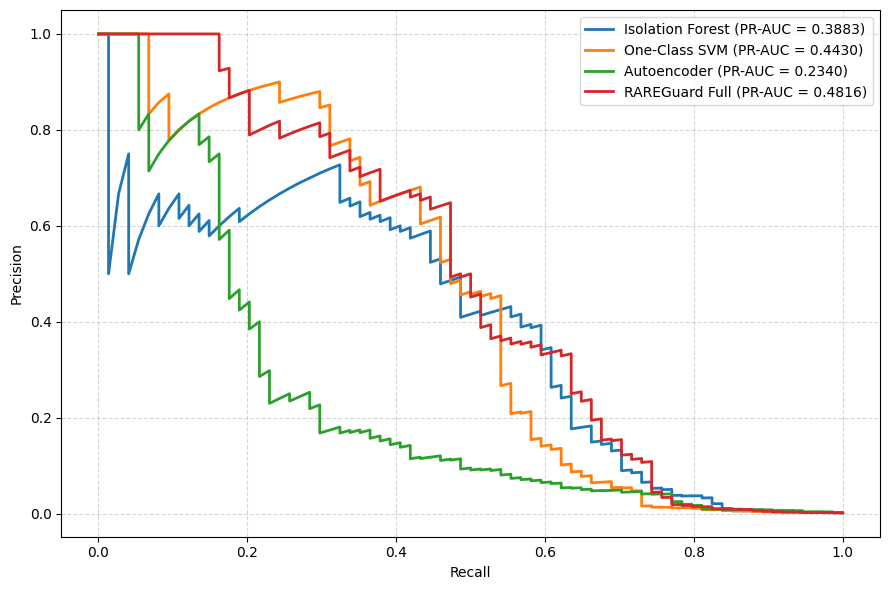

In [50]:

# FIGURE 2 — PRECISION–RECALL CURVES

scores_path = RESULTS_DIR/"representative_seed42_test_scores.csv"

scores_df = pd.read_csv(scores_path)

y_test = scores_df["y_test"].values
if_scores = scores_df["if_scores"].values
ocsvm_scores = scores_df["ocsvm_scores"].values
ae_scores = scores_df["ae_scores"].values
rareguard_scores = scores_df["rareguard_scores"].values

plt.figure(figsize=(9, 6))

models_scores = {
    "Isolation Forest": if_scores,
    "One-Class SVM": ocsvm_scores,
    "Autoencoder": ae_scores,
    "RAREGuard Full": rareguard_scores
}

for model_name, scores in models_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (PR-AUC = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    FIG_DIR/"figure_2_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

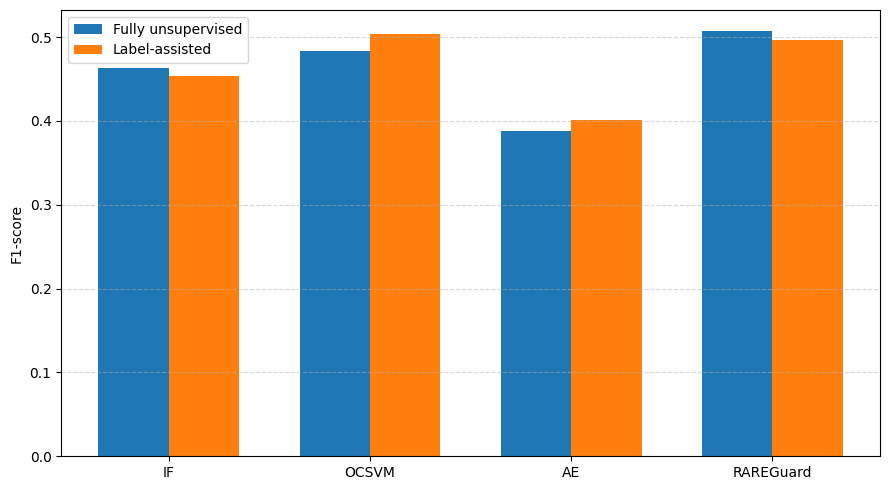

In [32]:
# FIGURE 3 — THRESHOLD STRATEGY COMPARISON


models_to_show = [
    "IF_Only",
    "OCSVM_Only",
    "AE_Only",
    "RAREGuard_Full"
]

df_plot = summary_mean[
    summary_mean["Experiment"].isin(models_to_show)
].copy()

pivot_df = df_plot.pivot(
    index="Experiment",
    columns="Threshold Mode",
    values="F1"
).loc[models_to_show]

x = np.arange(len(pivot_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    pivot_df["Fully unsupervised"],
    width,
    label="Fully unsupervised"
)

plt.bar(
    x + width / 2,
    pivot_df["Label-assisted"],
    width,
    label="Label-assisted"
)

plt.xticks(x, ["IF", "OCSVM", "AE", "RAREGuard"])
plt.ylabel("F1-score")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(FIG_DIR/ "figure_3_threshold_strategy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

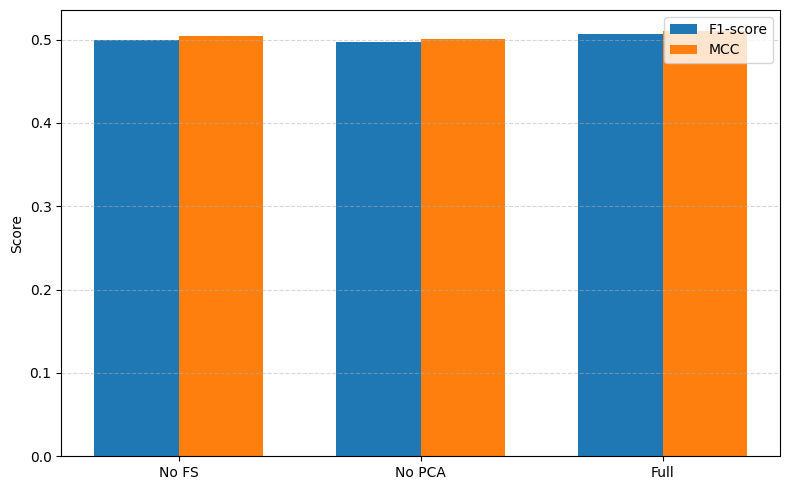

In [33]:
# FIGURE 4 — ABLATION STUDY


ablation_models = [
    "RAREGuard_No_FS",
    "RAREGuard_No_PCA",
    "RAREGuard_Full"
]

ablation_df = summary_mean[
    (summary_mean["Experiment"].isin(ablation_models)) &
    (summary_mean["Threshold Mode"] == "Fully unsupervised")
].copy()

ablation_df["Experiment"] = pd.Categorical(
    ablation_df["Experiment"],
    categories=ablation_models,
    ordered=True
)

ablation_df = ablation_df.sort_values("Experiment")

x = np.arange(len(ablation_df))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    ablation_df["F1"],
    width,
    label="F1-score"
)

plt.bar(
    x + width / 2,
    ablation_df["MCC"],
    width,
    label="MCC"
)

plt.xticks(x, ["No FS", "No PCA", "Full"])
plt.ylabel("Score")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(FIG_DIR/"figure_4_ablation_study.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

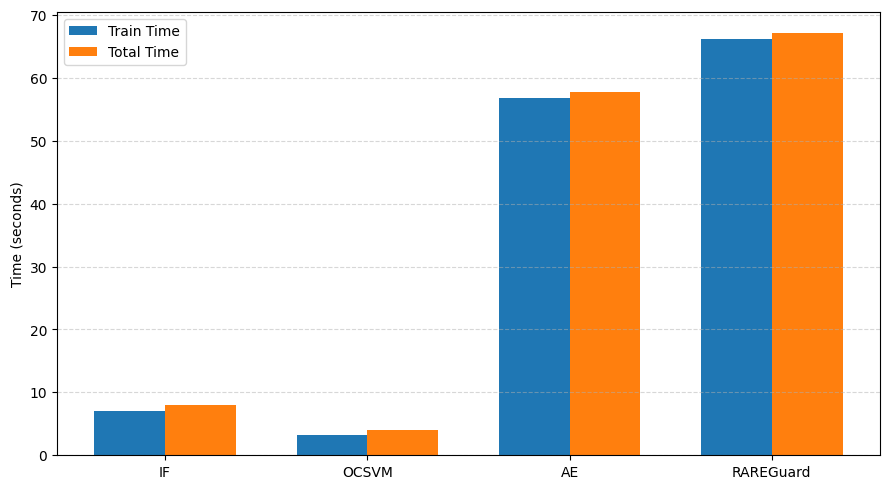

In [34]:
# FIGURE 6 — COMPUTATIONAL COST COMPARISON

models_to_show = [
    "IF_Only",
    "OCSVM_Only",
    "AE_Only",
    "RAREGuard_Full"
]

cost_df = summary_mean[
    (summary_mean["Experiment"].isin(models_to_show)) &
    (summary_mean["Threshold Mode"] == "Fully unsupervised")
].copy()

cost_df["Experiment"] = pd.Categorical(
    cost_df["Experiment"],
    categories=models_to_show,
    ordered=True
)

cost_df = cost_df.sort_values("Experiment")

x = np.arange(len(cost_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    cost_df["Train Time"],
    width,
    label="Train Time"
)

plt.bar(
    x + width / 2,
    cost_df["Total Time"],
    width,
    label="Total Time"
)

plt.xticks(x, ["IF", "OCSVM", "AE", "RAREGuard"])
plt.ylabel("Time (seconds)")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(FIG_DIR/"figure_6_computational_cost_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:

# SCALABILITY EXPERIMENT
# Generate and save scalability results

scalability_sizes = [
    50000,
    100000,
    150000,
    200000,
    250000,
    len(X_raw)
]

scalability_results = []

scalability_seed = 42

for sample_size in scalability_sizes:

    print(f"Running scalability test: {sample_size:,} transactions")

    set_seed(scalability_seed)

    # ---------------------------------
    # Draw a stratified sample
    # ---------------------------------
    if sample_size < len(X_raw):

        X_subset, _, y_subset, _ = train_test_split(
            X_raw,
            y_raw,
            train_size=sample_size,
            stratify=y_raw,
            random_state=scalability_seed
        )

    else:
        X_subset = X_raw.copy()
        y_subset = y_raw.copy()

    start_total = time.time()

    # ---------------------------------
    # Train / validation / test split
    # ---------------------------------
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_subset,
        y_subset,
        test_size=0.30,
        stratify=y_subset,
        random_state=scalability_seed
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=scalability_seed
    )

    # ---------------------------------
    # Full RAREGuard feature pipeline
    # ---------------------------------
    (
        X_train_best,
        X_val_best,
        X_test_best,
        selected_features,
        pca_dims
    ) = prepare_features(
        X_train,
        X_val,
        X_test,
        y_train,
        seed=scalability_seed,
        use_feature_selection=True,
        use_pca=True
    )

    # ---------------------------------
    # Run full RAREGuard
    # ---------------------------------
    val_scores, test_scores, train_time = run_models(
        X_train_best,
        X_val_best,
        X_test_best,
        y_train,
        y_val,
        y_test,
        seed=scalability_seed,
        model_mode="RAREGuard"
    )

    # ---------------------------------
    # Fully unsupervised threshold
    # ---------------------------------
    threshold = pick_threshold_unsupervised(
        val_scores,
        contamination=0.002
    )

    metrics = evaluate_scores(
        y_test,
        test_scores,
        threshold
    )

    total_time = time.time() - start_total

    scalability_results.append({
        "Sample Size": sample_size,
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
        "PR_AUC": metrics["PR_AUC"],
        "ROC_AUC": metrics["ROC_AUC"],
        "MCC": metrics["MCC"],
        "Train Time": train_time,
        "Total Time": total_time,
        "Selected Features": len(selected_features),
        "PCA Dimensions": pca_dims
    })

    gc.collect()


# Convert to dataframe
scalability_df = pd.DataFrame(scalability_results)

display(scalability_df)


# Save in the current results folder
scalability_path = RESULTS_DIR/"scalability_analysis.csv"

scalability_df.to_csv(
    scalability_path,
    index=False
)

print("Saved:", scalability_path)

Running scalability test: 50,000 transactions
Running scalability test: 100,000 transactions
Running scalability test: 150,000 transactions
Running scalability test: 200,000 transactions
Running scalability test: 250,000 transactions
Running scalability test: 284,807 transactions


,Sample Size,Precision,Recall,F1,PR_AUC,ROC_AUC,MCC,Train Time,Total Time,Selected Features,PCA Dimensions
0,50000,0.478261,0.846154,0.611111,0.762848,0.967533,0.635366,13.567120,13.867077,20,13
1,100000,0.384615,0.576923,0.461538,0.466240,0.927952,0.469951,25.361878,25.731609,20,13
2,150000,0.476190,0.512821,0.493827,0.433346,0.945217,0.493255,35.440381,35.896181,20,12
3,200000,0.568627,0.568627,0.568627,0.465429,0.947968,0.567893,41.555714,42.106897,20,12
4,250000,0.447761,0.461538,0.454545,0.420714,0.918948,0.453636,59.950332,60.621466,20,12
5,284807,0.493151,0.486486,0.489796,0.481565,0.913364,0.488928,71.631345,72.401603,20,12


Saved: /content/drive/MyDrive/PhD/RAREGuard_v5/results/scalability_analysis.csv


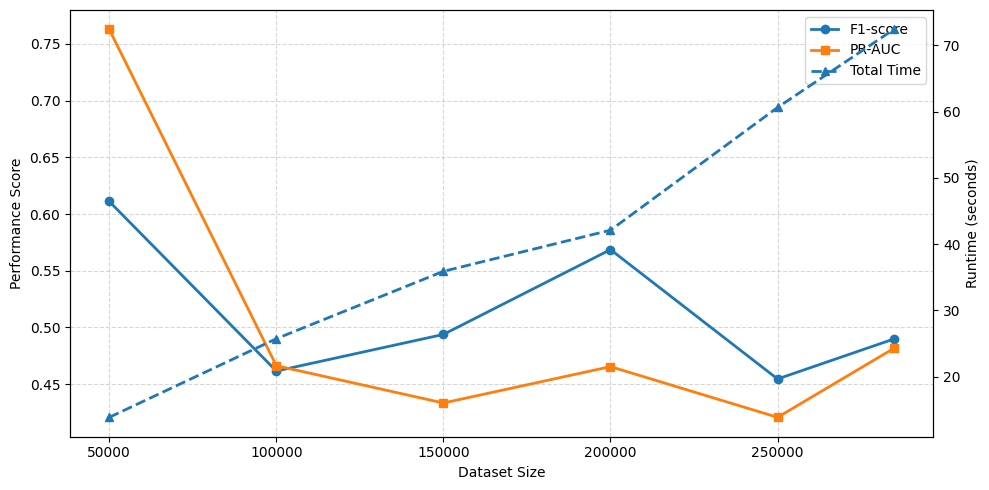

In [52]:
# FIGURE 7 — SCALABILITY ANALYSIS

scalability_path = RESULTS_DIR/"scalability_analysis.csv"

scalability_df = pd.read_csv(
    scalability_path
)

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(
    scalability_df["Sample Size"],
    scalability_df["F1"],
    marker="o",
    linewidth=2,
    label="F1-score"
)

ax1.plot(
    scalability_df["Sample Size"],
    scalability_df["PR_AUC"],
    marker="s",
    linewidth=2,
    label="PR-AUC"
)

ax1.set_xlabel("Dataset Size")
ax1.set_ylabel("Performance Score")
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()

ax2.plot(
    scalability_df["Sample Size"],
    scalability_df["Total Time"],
    marker="^",
    linewidth=2,
    linestyle="--",
    label="Total Time"
)

ax2.set_ylabel("Runtime (seconds)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.tight_layout()

plt.savefig(FIG_DIR/ "figure_7_scalability_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

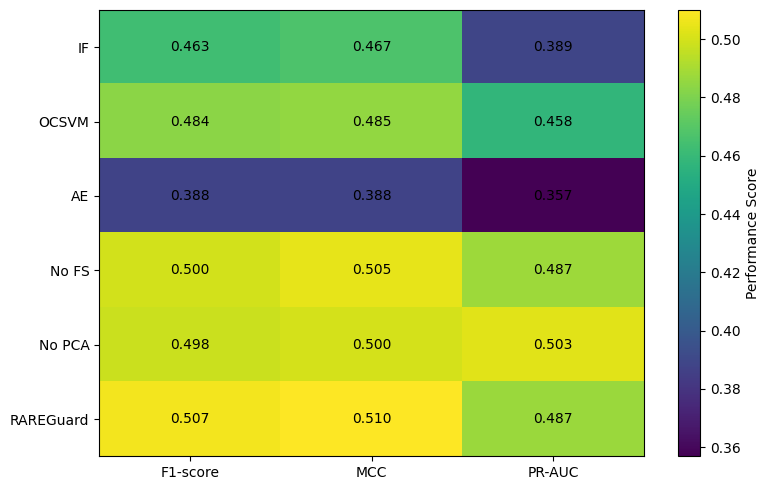

In [37]:
# FIGURE 8 — PERFORMANCE HEATMAP

heatmap_models = [
    "IF_Only",
    "OCSVM_Only",
    "AE_Only",
    "RAREGuard_No_FS",
    "RAREGuard_No_PCA",
    "RAREGuard_Full"
]

heatmap_df = summary_mean[
    (summary_mean["Experiment"].isin(heatmap_models)) &
    (summary_mean["Threshold Mode"] == "Fully unsupervised")
].copy()

heatmap_df["Experiment"] = pd.Categorical(
    heatmap_df["Experiment"],
    categories=heatmap_models,
    ordered=True
)

heatmap_df = heatmap_df.sort_values("Experiment")

data = heatmap_df[["F1", "MCC", "PR_AUC"]].values

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(data, aspect="auto")

ax.set_xticks(np.arange(3))
ax.set_xticklabels(["F1-score", "MCC", "PR-AUC"])

ax.set_yticks(np.arange(len(heatmap_models)))
ax.set_yticklabels(["IF", "OCSVM", "AE", "No FS", "No PCA", "RAREGuard"])

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(
            j,
            i,
            f"{data[i, j]:.3f}",
            ha="center",
            va="center"
        )

cbar = plt.colorbar(im)
cbar.set_label("Performance Score")

plt.tight_layout()

plt.savefig(
    FIG_DIR/"figure_8_performance_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()